In [1]:
from collections import Counter
from itertools import chain
import matplotlib.pyplot as plt
import nltk
from nltk.lm import Laplace
from nltk.lm.preprocessing import padded_everygram_pipeline
from nltk.lm import Vocabulary
import numpy as np
import pandas as pd
from pathlib import Path
import re
from scipy.spatial.distance import jensenshannon
import seaborn as sns

In [2]:
# Find all CSV files in the data folder

DATA_PATH = Path("../data/Translated")
csv_files = sorted(DATA_PATH.glob("*.csv"))

print(f"Found {len(csv_files)} files:")
for f in csv_files:
    print(f.name)

Found 17 files:
Speeches_ALDE_Cleaned_Translated.csv
Speeches_CZ_Cleaned_Translated.csv
Speeches_DE_Cleaned_Translated.csv
Speeches_ECB_Cleaned_Translated.csv
Speeches_ECR_Cleaned_Translated.csv
Speeches_EC_Cleaned_Translated.csv
Speeches_EP_Cleaned_Translated.csv
Speeches_EUCouncil_Cleaned_Translated.csv
Speeches_FR_Cleaned_Translated.csv
Speeches_GR_Cleaned_Translated.csv
Speeches_IMF_Cleaned_Translated.csv
Speeches_IT_Cleaned_Translated.csv
Speeches_NL_Cleaned_Translated.csv
Speeches_PL_Cleaned_Translated.csv
Speeches_PO_Cleaned_Translated.csv
Speeches_SP_Cleaned_Translated.csv
Speeches_UK_Cleaned_Translated.csv


In [3]:
# Load all CSV files into DataFrame

ALL_COLUMNS = ["title", "date", "location", "speaker", "word_count", "raw", "raw_text", "original", "lang"]
USE_COLUMNS = ["title", "date", "location", "speaker", "raw"]

def clean_sentence(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def split_sentences(text: str) -> list[str]:
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [clean_sentence(s) for s in sentences if s.strip()]

def load_speech_csv(path: Path) -> pd.DataFrame:
    nation = path.stem.split("_")[1]
    df = pd.read_csv(path, header=None, names=ALL_COLUMNS, usecols=USE_COLUMNS)
    df["nation"] = nation
    df["sentences"] = df["raw"].apply(split_sentences)
    return df

corpus = pd.concat([load_speech_csv(f) for f in csv_files], ignore_index=True)
print(f"Loaded {len(corpus)} speeches:")
corpus.head()

Loaded 6106 speeches:


,title,date,location,speaker,raw,nation,sentences
0,Rede von Guy Verhofstadt anläßlich des FDP Eur...,23-06-2013,European Parliament,Guy Verhofstadt,"Love Nadja, dear friends,Dear Sir or Madam,rea...",ALDE,[love nadja dear friends dear sir or madam rea...
1,Speech by Guy Verhofstadt - Intervention in pl...,05-02-2013,European Parliament,Guy Verhofstadt,Intervention Guy VerhofstadtNovember 21 2012Vi...,ALDE,[intervention guy verhofstadtnovember 21 2012v...
2,Speech by Guy Verhofstadt on the future of Europe,09-05-2012,European Parliament,Guy Verhofstadt,"Dear President, Dear colleagues,Let me paraphr...",ALDE,[dear president dear colleagues let me paraphr...
3,Speech by Guy Verhofstadt on PPV,12-03-2012,European Parliament,Guy Verhofstadt,"My group, President, for the initiative of Mr ...",ALDE,[my group president for the initiative of mr w...
4,Le Grand Direct de Guy Verhofstadt,07-03-2012,European Parliament,Guy Verhofstadt,Guy Verhofstadt Live dupuis RTL-TVI answering ...,ALDE,[guy verhofstadt live dupuis rtl tvi answering...


In [4]:
corpus.groupby("nation").size().sort_values(ascending=False).rename("speech_count")

nation
FR           1451
EP           1064
SP            996
IT            804
DE            580
GR            390
NL            260
CZ            234
EC            149
PO            133
ECB            18
EUCouncil      16
ALDE            6
PL              4
ECR             1
Name: speech_count, dtype: int64

In [5]:
# Exporting corpus for SRILM

output_directory = Path("../output/countries")
output_directory.mkdir(parents=True, exist_ok=True)

for nation, group in corpus.groupby("nation"):
    out_file = output_directory / f"{nation}.txt"
    
    with open(out_file, "w", encoding="utf-8") as f:
        for sentence_list in group["sentences"]:
            for sent in sentence_list:
                f.write(sent + "\n")

In [6]:

def tokenize_sentences(sentences: list[str]) -> list[list[str]]:
    return [s.split() for s in sentences if s.strip()]

corpus["tokens"] = corpus["sentences"].apply(tokenize_sentences)

In [7]:
all_tokens = chain.from_iterable(
    chain.from_iterable(token_lists) for token_lists in corpus["tokens"]
)
universal_vocab = Vocabulary(all_tokens, unk_cutoff=1)

print(f"Universal vocabulary size: {len(universal_vocab):,} tokens")

Universal vocabulary size: 62,377 tokens


In [8]:
N = 2
nation_models: dict[str, Laplace] = {}

for nation, group in corpus.groupby("nation"):
    nation_sentences = list(chain.from_iterable(group["tokens"]))
    train_data, _ = padded_everygram_pipeline(N, nation_sentences)

    model = Laplace(N, vocabulary=universal_vocab)
    model.fit(train_data)

    nation_models[nation] = model
    print(f"{nation:>10}: {len(nation_sentences):>7,} sentences")

print("-" * 30)
print(f"Built {len(nation_models)} nation-level {N}-gram models")

      ALDE:     246 sentences
        CZ:   4,935 sentences
        DE:  59,855 sentences
        EC:   9,541 sentences
       ECB:   1,469 sentences
       ECR:      95 sentences
        EP:  12,620 sentences
 EUCouncil:   1,652 sentences
        FR: 165,403 sentences
        GR:  43,631 sentences
        IT:  42,070 sentences
        NL:  15,475 sentences
        PL:   1,017 sentences
        PO:   9,053 sentences
        SP: 119,197 sentences
------------------------------
Built 15 nation-level 2-gram models


In [9]:
test_context = ["european"]
test_word = "union"

print(f"P('{test_word}' | '{test_context[-1]}')")
print("-" * 30)
for nation, model in sorted(nation_models.items()):
    score = model.score(test_word, test_context)
    print(f"{nation:>10}: {score:.6f}")

P('union' | 'european')
------------------------------
      ALDE: 0.000144
        CZ: 0.005681
        DE: 0.017810
        EC: 0.005993
       ECB: 0.000256
       ECR: 0.000016
        EP: 0.010697
 EUCouncil: 0.000735
        FR: 0.007758
        GR: 0.010481
        IT: 0.011511
        NL: 0.001544
        PL: 0.000336
        PO: 0.001350
        SP: 0.047851


In [ ]:
def get_unigram_vector(model, vocab_words):
    counts = np.array([model.counts[1][w] for w in vocab_words], dtype=np.float64)
    counts += 1
    return counts / counts.sum()

vocab_words = [w for w in universal_vocab if w not in ("<UNK>", "<s>", "</s>")]
nations = sorted(nation_models.keys())

probability_matrix = np.vstack([
    get_unigram_vector(nation_models[n], vocab_words)
    for n in nations
])

print(f"Probability matrix shape: {probability_matrix.shape}")

Probability matrix shape: (15, 62376)


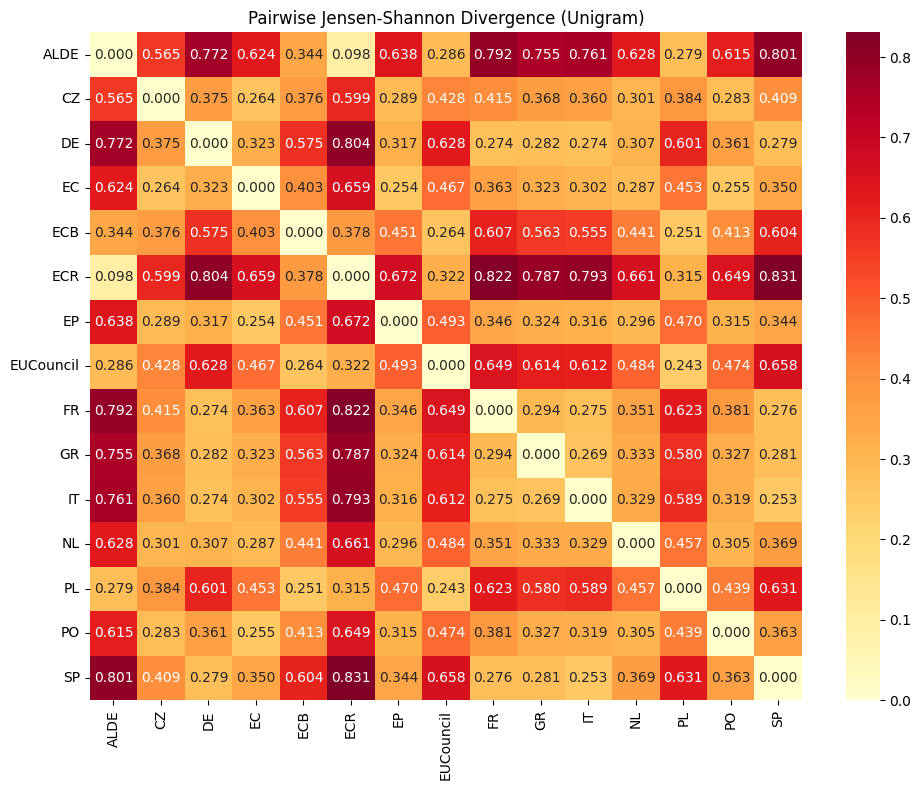

In [ ]:
n = len(nations)
jsd_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(i + 1, n):
        d = jensenshannon(probability_matrix[i], probability_matrix[j], base=2)
        jsd_matrix[i, j] = jsd_matrix[j, i] = d

jsd_df = pd.DataFrame(jsd_matrix, index=nations, columns=nations)

plt.figure(figsize=(10, 8))
sns.heatmap(jsd_df, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Pairwise Jensen-Shannon Divergence (Unigram)")
plt.tight_layout()
plt.show()